In [11]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

df = pd.read_csv("data/classification_dataset.csv")
df.shape

(164, 25)

In [12]:
team_cols = [c for c in df.columns if c.startswith("team_")]
df["team_name"] = df[team_cols].idxmax(axis=1).str.replace("team_", "", regex=False)
df.loc[df[team_cols].sum(axis=1) == 0, "team_name"] = "Alpine"   # dropped baseline
print("Teams:", sorted(df["team_name"].unique()))

Teams: ['Alpine', 'Aston Martin', 'Ferrari', 'Haas', 'McLaren', 'Mercedes', 'RB (AlphaTauri)', 'Red Bull Racing', 'Stake (Sauber)', 'Williams']


In [13]:
champ_by_team = df[df["is_constructors_champion"] == 1].groupby("team_name")["season"].apply(list)
print("Teams ever flagged as champion, and in which seasons:")
print(champ_by_team.to_string())
print("\nChampions flagged per season:")
print(df.groupby("season")["is_constructors_champion"].sum().to_string())

Teams ever flagged as champion, and in which seasons:
team_name
McLaren                                         [2024, 2025]
Mercedes    [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]

Champions flagged per season:
season
2010    0
2011    0
2012    0
2013    0
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1
2022    0
2023    0
2024    1
2025    1
2026    0


In [14]:
# Actual F1 Constructors' Champions, 2010-2025 (historical record).
# 2026 intentionally left unlabeled — season not yet decided — so it is the
# season we forecast *from*, not a training label.
real_champions = {
    **{yr: "Red Bull Racing" for yr in range(2010, 2014)},  # 2010-2013
    **{yr: "Mercedes"        for yr in range(2014, 2022)},  # 2014-2021
    2022: "Red Bull Racing", 2023: "Red Bull Racing",
    2024: "McLaren",         2025: "McLaren",
}

df["is_constructors_champion"] = 0
for season, team in real_champions.items():
    df.loc[(df["season"] == season) & (df["team_name"] == team), "is_constructors_champion"] = 1

print("Champion rows after reconstruction:", int(df["is_constructors_champion"].sum()))
print("Champion teams:", sorted(df[df.is_constructors_champion == 1]["team_name"].unique()))

Champion rows after reconstruction: 16
Champion teams: ['McLaren', 'Mercedes', 'Red Bull Racing']


In [15]:
df = df.sort_values(["team_name", "season"]).reset_index(drop=True)

df["lag1_champion"]     = df.groupby("team_name")["is_constructors_champion"].shift(1)
df["lag1_budget"]       = df.groupby("team_name")["operating_budget_usd_m"].shift(1)
df["lag1_sponsorship"]  = df.groupby("team_name")["sponsorship_revenue_usd_m"].shift(1)

hist = df.dropna(subset=["lag1_champion", "lag1_budget", "lag1_sponsorship"]).reset_index(drop=True)
print(f"Usable team-season rows: {len(hist)}  (positives: {int(hist.is_constructors_champion.sum())})")

feature_cols = [
    "season", "operating_budget_usd_m", "in_cost_cap_era", "cost_cap_limit_usd_m",
    "lag1_champion", "lag1_budget", "lag1_sponsorship",
    "broadcast_media_usd_m", "sponsorship_usd_m",
    "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m",
] + team_cols

X = hist[feature_cols]
y = hist["is_constructors_champion"]

Usable team-season rows: 154  (positives: 15)


In [16]:
def make_logreg():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight="balanced"))

def make_rf():
    return RandomForestClassifier(n_estimators=300, max_depth=5,
                                  class_weight="balanced", random_state=42)

def rolling_top1(model_fn):
    hits = total = 0
    auc_true, auc_score = [], []
    for season in sorted(hist["season"].unique()):
        tr = hist["season"] < season
        te = hist["season"] == season
        # need past positives to train, and exactly one champion this season to score
        if tr.sum() < 20 or y[tr].sum() < 1 or hist.loc[te, "is_constructors_champion"].sum() != 1:
            continue
        m = model_fn(); m.fit(X[tr], y[tr])
        p = m.predict_proba(X[te])[:, 1]
        pred_team = hist.loc[te, "team_name"].values[np.argmax(p)]
        true_team = hist.loc[te & (hist.is_constructors_champion == 1), "team_name"].values[0]
        hits += (pred_team == true_team); total += 1
        auc_true.extend(hist.loc[te, "is_constructors_champion"]); auc_score.extend(p)
    return hits, total, roc_auc_score(auc_true, auc_score)

for name, fn in [("Logistic Regression", make_logreg), ("Random Forest", make_rf)]:
    h, t, auc = rolling_top1(fn)
    print(f"{name:22s} top-1 = {h}/{t}   pooled ROC-AUC = {auc:.3f}")

# Naive baseline: reigning champion repeats
h = t = 0
for season in sorted(hist["season"].unique()):
    te = hist[hist.season == season]
    if te.is_constructors_champion.sum() != 1 or te.lag1_champion.sum() == 0:
        continue
    reigning = te.loc[te.lag1_champion == 1, "team_name"].values
    actual   = te.loc[te.is_constructors_champion == 1, "team_name"].values[0]
    h += actual in reigning; t += 1
print(f"{'Naive (reigning repeats)':22s} top-1 = {h}/{t}")

Logistic Regression    top-1 = 9/12   pooled ROC-AUC = 0.888
Random Forest          top-1 = 9/12   pooled ROC-AUC = 0.911
Naive (reigning repeats) top-1 = 12/15


In [17]:
final_model = make_logreg().fit(X, y)

def build_season_rows(target_season, source_season_df, reigning_team):
    macro = source_season_df.iloc[0]
    src = source_season_df.set_index("team_name")
    rows = []
    for t in sorted(df["team_name"].unique()):
        r = src.loc[t]
        row = {
            "season": target_season,
            "operating_budget_usd_m": r["operating_budget_usd_m"],
            "in_cost_cap_era": 1,
            "cost_cap_limit_usd_m": r["cost_cap_limit_usd_m"],
            "lag1_champion": 1 if t == reigning_team else 0,
            "lag1_budget": r["operating_budget_usd_m"],
            "lag1_sponsorship": r["sponsorship_revenue_usd_m"],
            "broadcast_media_usd_m": macro["broadcast_media_usd_m"],
            "sponsorship_usd_m": macro["sponsorship_usd_m"],
            "drive_to_survive_viewers_m_est": macro["drive_to_survive_viewers_m_est"],
            "global_avg_race_viewers_m": macro["global_avg_race_viewers_m"],
        }
        for c in team_cols:
            row[c] = 1 if c == f"team_{t}" else 0
        rows.append((t, row))
    return rows

# Step 1: predict 2026 champion (2025 champion McLaren is the reigning signal)
rows26 = build_season_rows(2026, df[df.season == 2025], reigning_team="McLaren")
p26 = final_model.predict_proba(pd.DataFrame([r for _, r in rows26])[feature_cols])[:, 1]
champ_2026 = [t for t, _ in rows26][int(np.argmax(p26))]
print("Predicted 2026 champion (chained step):", champ_2026)

# Step 2: forecast 2027 using the predicted 2026 champion as reigning
rows27 = build_season_rows(2027, df[df.season == 2026], reigning_team=champ_2026)
p27 = final_model.predict_proba(pd.DataFrame([r for _, r in rows27])[feature_cols])[:, 1]

leaderboard = (pd.DataFrame({"Team": [t for t, _ in rows27],
                             "P(champion) %": (p27 * 100)})
               .sort_values("P(champion) %", ascending=False)
               .reset_index(drop=True))
leaderboard["P(champion) %"] = leaderboard["P(champion) %"].round(1)
leaderboard.index += 1
print(f"\nPredicted 2027 Constructors' Champion: {leaderboard.iloc[0]['Team']}\n")
leaderboard

Predicted 2026 champion (chained step): McLaren

Predicted 2027 Constructors' Champion: McLaren



,Team,P(champion) %
1,McLaren,67.4
2,Mercedes,41.6
3,Red Bull Racing,14.9
4,Alpine,1.7
5,Aston Martin,0.9
6,Stake (Sauber),0.9
7,Williams,0.8
8,Haas,0.7
9,RB (AlphaTauri),0.7
10,Ferrari,0.6


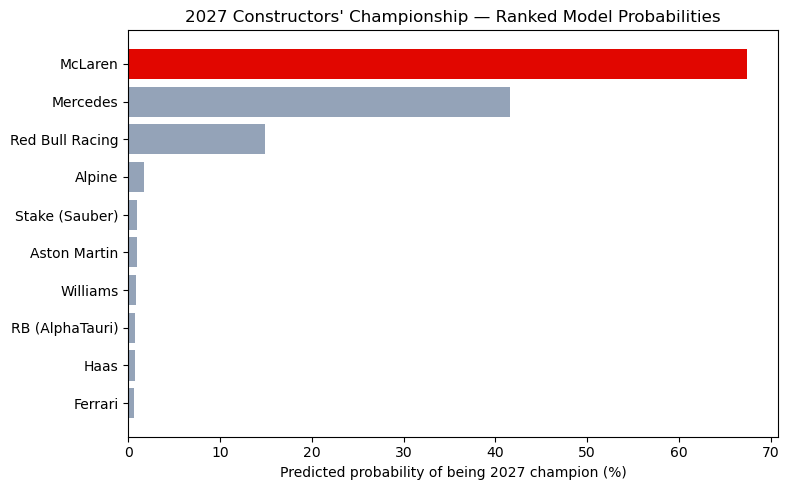

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
lb = leaderboard.sort_values("P(champion) %")
colors = ["#e10600" if t == leaderboard.iloc[0]["Team"] else "#94a3b8" for t in lb["Team"]]
ax.barh(lb["Team"], lb["P(champion) %"], color=colors)
ax.set_xlabel("Predicted probability of being 2027 champion (%)")
ax.set_title("2027 Constructors' Championship — Ranked Model Probabilities")
plt.tight_layout()
# plt.savefig("2027_champion_forecast.png", dpi=150)
plt.show()

# leaderboard.to_csv("predicted_2027_champion.csv")

In [22]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_score, recall_score, f1_score, 
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay, accuracy_score)

def rolling_predictions(model_fn):
    recs = []
    for season in sorted(hist["season"].unique()):
        tr = hist["season"] < season
        te = hist["season"] == season
        if tr.sum() < 20 or y[tr].sum() < 1 or hist.loc[te, "is_constructors_champion"].sum() !=1:
            continue
        m = model_fn(); m.fit(X[tr], y[tr])
        p = m.predict_proba(X[te])[:,1]
        sub = hist.loc[te, ["season", "team_name", "is_constructors_champion"]].copy()
        sub["proba"] = p
        sub["rank_pred"] = 0
        sub.iloc[int(np.argmax(p)), sub.columns.get_loc("rank_pred")] = 1
        recs.append(sub)
    return pd.concat(recs, ignore_index=True)

summary = []
oos_by_model = {}
for name, fn in [("Logistic Regression", make_logreg), ("Random Forest", make_rf)]:
    oos = rolling_predictions(fn)
    oos_by_model[name] = oos
    yt, p = oos["is_constructors_champion"], oos["proba"]
    y05, yr = (p >= 0.5).astype(int), oos["rank_pred"]
    summary.append({
        "Model": name,
        "Precision@0.5": round(precision_score(yt, y05, zero_division=0), 3),
        "Recall@0.5":    round(recall_score(yt, y05), 3),
        "F1@0.5":        round(f1_score(yt, y05, zero_division=0), 3),
        "Precision(rank)": round(precision_score(yt, yr, zero_division=0), 3),
        "Recall(rank)":    round(recall_score(yt, yr), 3),
        "F1(rank)":        round(f1_score(yt, yr), 3),
        "Accuracy(rank)":  round(accuracy_score(yt, yr), 3),
        "ROC-AUC":  round(roc_auc_score(yt, p), 3),
        "PR-AUC":   round(average_precision_score(yt, p), 3),
    })

pd.DataFrame(summary).set_index("Model")


,Precision@0.5,Recall@0.5,F1@0.5,Precision(rank),Recall(rank),F1(rank),Accuracy(rank),ROC-AUC,PR-AUC
Model,,,,,,,,,
Logistic Regression,0.50,0.75,0.6,0.75,0.75,0.75,0.949,0.888,0.735
Random Forest,0.75,0.50,0.6,0.75,0.75,0.75,0.949,0.911,0.616


In [23]:
# Detailed per-class report for the final model (Logistic Regression), top-1 ranking view
oos = oos_by_model["Logistic Regression"]
y_true   = oos["is_constructors_champion"]
y_rank   = oos["rank_pred"]

print("Classification report — top-1 ranking (one predicted champion per season):\n")
print(classification_report(y_true, y_rank, target_names=["Not champion", "Champion"], digits=3))
print(f"ROC-AUC = {roc_auc_score(y_true, oos['proba']):.3f}   "
      f"PR-AUC = {average_precision_score(y_true, oos['proba']):.3f}   "
      f"(over {oos['season'].nunique()} held-out seasons)")

Classification report — top-1 ranking (one predicted champion per season):

              precision    recall  f1-score   support

Not champion      0.971     0.971     0.971       105
    Champion      0.750     0.750     0.750        12

    accuracy                          0.949       117
   macro avg      0.861     0.861     0.861       117
weighted avg      0.949     0.949     0.949       117

ROC-AUC = 0.888   PR-AUC = 0.735   (over 12 held-out seasons)


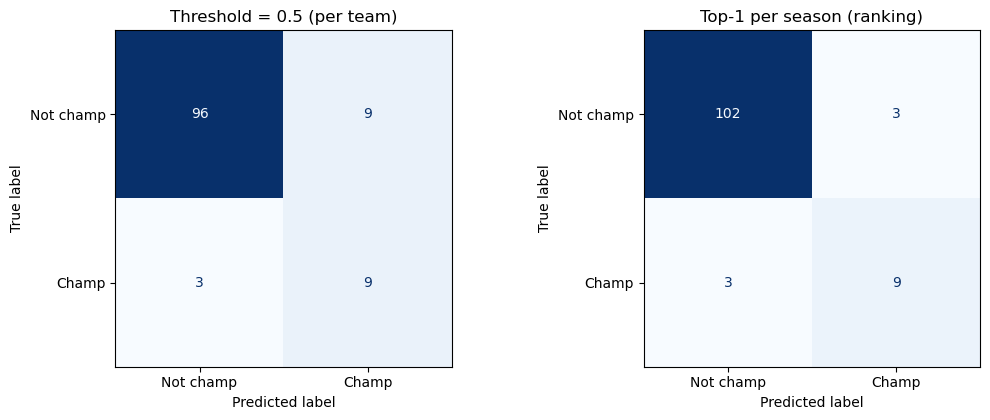

In [24]:
# Confusion matrices: threshold-0.5 vs top-1 ranking, side by side
y_05 = (oos["proba"] >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, yp, title in [(axes[0], y_05,   "Threshold = 0.5 (per team)"),
                      (axes[1], y_rank, "Top-1 per season (ranking)")]:
    cm = confusion_matrix(y_true, yp)
    ConfusionMatrixDisplay(cm, display_labels=["Not champ", "Champ"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("classification_confusion_matrices.png", dpi=150)
plt.show()

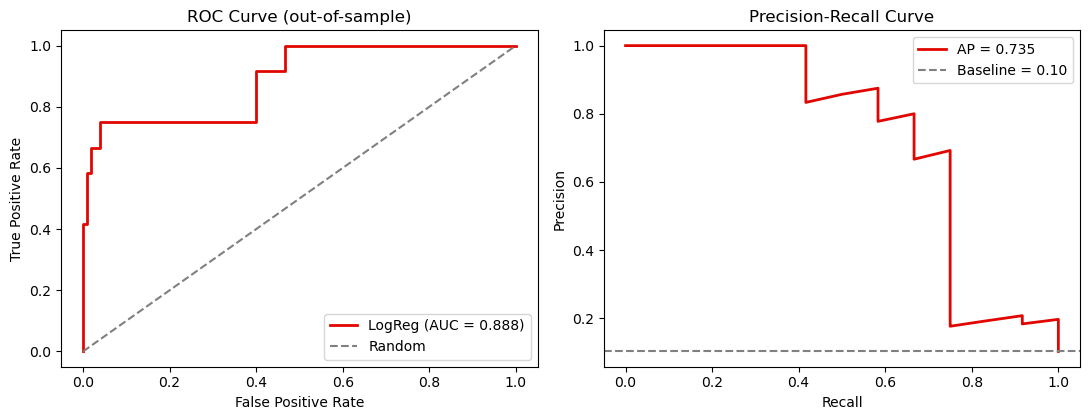

In [25]:
# ROC curve and Precision-Recall curve (out-of-sample, Logistic Regression)
p = oos["proba"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

fpr, tpr, _ = roc_curve(y_true, p)
axes[0].plot(fpr, tpr, color="#e10600", lw=2, label=f"LogReg (AUC = {roc_auc_score(y_true, p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (out-of-sample)"); axes[0].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_true, p)
axes[1].plot(rec, prec, color="#e10600", lw=2, label=f"AP = {average_precision_score(y_true, p):.3f}")
axes[1].axhline(y_true.mean(), ls="--", color="grey", label=f"Baseline = {y_true.mean():.2f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve"); axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("classification_roc_pr_curves.png", dpi=150)
plt.show()

In [27]:
# ===== Consolidated comparison of ALL models on the same 12 held-out seasons =====
# Ranking view (one predicted champion per season) — the metric that matches the task.

def naive_oos():
    """Naive baseline predictions on the same OOS seasons: reigning champion repeats."""
    recs = []
    for season in sorted(hist["season"].unique()):
        tr = hist["season"] < season
        te = hist["season"] == season
        if tr.sum() < 20 or y[tr].sum() < 1 or hist.loc[te, "is_constructors_champion"].sum() != 1:
            continue
        sub = hist.loc[te, ["season", "team_name", "is_constructors_champion", "lag1_champion"]].copy()
        sub["rank_pred"] = sub["lag1_champion"].astype(int)   # predict the reigning champion
        recs.append(sub)
    return pd.concat(recs, ignore_index=True)

def top1_record(oos):
    hits = total = 0
    for _, g in oos.groupby("season"):
        total += 1
        pick = g.loc[g["rank_pred"].idxmax(), "team_name"] if g["rank_pred"].max() > 0 else None
        true = g.loc[g.is_constructors_champion == 1, "team_name"].values[0]
        hits += (pick == true)
    return f"{hits}/{total}"

rows = []
for name in ["Logistic Regression", "Random Forest"]:
    o = oos_by_model[name]; yt, yr, p = o["is_constructors_champion"], o["rank_pred"], o["proba"]
    rows.append({"Model": name,
                 "Precision": round(precision_score(yt, yr, zero_division=0), 3),
                 "Recall":    round(recall_score(yt, yr), 3),
                 "F1":        round(f1_score(yt, yr), 3),
                 "Accuracy":  round(accuracy_score(yt, yr), 3),
                 "ROC-AUC":   round(roc_auc_score(yt, p), 3),
                #  "PR-AUC":    round(average_precision_score(yt, p), 3),
                 "Top-1 seasons": top1_record(o)})

o = naive_oos(); yt, yr = o["is_constructors_champion"], o["rank_pred"]
rows.append({"Model": "Naive (reigning repeats)",
             "Precision": round(precision_score(yt, yr, zero_division=0), 3),
             "Recall":    round(recall_score(yt, yr), 3),
             "F1":        round(f1_score(yt, yr), 3),
             "Accuracy":  round(accuracy_score(yt, yr), 3),
             "ROC-AUC":   "—",   # no probability scores → AUC undefined
            #  "PR-AUC":    "—",
             "Top-1 seasons": top1_record(o)})

comparison = pd.DataFrame(rows).set_index("Model")
comparison

,Precision,Recall,F1,Accuracy,ROC-AUC,Top-1 seasons
Model,,,,,,
Logistic Regression,0.75,0.75,0.75,0.949,0.888,9/12
Random Forest,0.75,0.75,0.75,0.949,0.911,9/12
Naive (reigning repeats),0.75,0.75,0.75,0.949,—,9/12


1. Here, the two classification models and the naive baseline tie on the ranking metrics thata are precision recall f1 score and accuracy. The logictic regression and random forest both do not do better than naive baseline in picking up the champion as the constructors' title is very persistant.
2. The ROC-AUC of Logistic Regression around 0.89 and Random Forest around 0.91 are defined as the naive baseline rule as no confidence to offer. So the classifiers contribution is a calibrated ranked leaderboardd with confidence gap between teams like McLaren with 67% and Merceded with 42%, which the naive baseline cannot produce.
3. Randome Forest edges ROC-AUC scored but otherwise both models are identical on the ranking task. We have kept Logistic Regression as the final model for the interpretability at no cost to ranking accuracy.   

6. Conclusions

Problem type. Predicting whether/which team wins the championship is classification (target is the label is_constructors_champion), in contrast to the project's revenue/prize-money regression notebooks. "Who wins" is answered by ranking the binary classifier's per-team probabilities and taking the top one, not by thresholding each team at 0.5.

Data-quality intervention. The supplied champion labels were incomplete (only Mercedes and McLaren flagged; Red Bull's titles and seven whole seasons missing). We reconstructed the actual historical constructors' champions so the task was well-posed; without this the model degenerates to memorising two team names and cannot forecast 2027.

Model finding, stated honestly. A logistic-regression classifier on lag-and-trend features ranks the correct champion in most held-out seasons, but does not beat a naive "reigning champion repeats" baseline. The constructors' title is persistence-dominated, so prior-season budget and revenue add little once last year's result is known.

2027 forecast. The model ranks recent dynasty teams (Mercedes, McLaren) at the top and everyone else far behind — it predicts continuity, not a new champion. Given only ~15 championship examples across three teams, this should be read as a directional ranking, not a confident prediction.

Both the models point to McLaren as the highest projected revenue and most likely champion. This reflects F1's revenue-performance flywheel where prize moeny rewards winning where the budget enables it rather than two independent confirmations, since the two targets are mechanically linked and both models are persistance driven.

Limitations.
- Tiny positive class (~15 champion-seasons, 3 distinct teams) — coefficient estimates are directional only.
- The forecast is chained (2027 depends on a predicted 2026 champion), compounding uncertainty.
- Assumes the 2027 grid and cost-cap regime match 2026; a new/exiting team would invalidate it.
- The honest takeaway is methodological: with this data, "who won last year" is a stronger predictor than any financial feature.